# 03 - Exploratory data analysis

Severity distribution (original 1-4 and binary), correlation heatmap of the 25 features most correlated with the binary target, high-severity rate by road type, and the speed-violation risk score by severity class.

**Run after 02.** Input: `outputs/Processed_Data/processed_full_dataset.csv`. Output: four PNG figures in `outputs/Figures/`.

*Source: `CODE/03_eda.py`*

## 0. Environment

In [1]:
import sys, importlib
print("Python", sys.version.split()[0])
for pkg in ['pandas', 'numpy', 'matplotlib', 'seaborn']:
    try:
        mod = importlib.import_module(pkg)
        print(f"{pkg:<12}{getattr(mod, '__version__', '?')}")
    except ImportError:
        print(f"{pkg:<12}NOT INSTALLED")

Python 3.13.18
pandas      2.2.3
numpy       2.1.3
matplotlib  3.10.0
seaborn     0.13.2


## 1. Imports and configuration

In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)  # display only (e.g. seaborn palette notice)
warnings.filterwarnings("ignore", message=".*'str' dtypes are included.*")  # display only (pandas 3 select_dtypes notice)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---- values below are copied verbatim from config.py (inlined so this notebook runs standalone) ----
RANDOM_SEED = 42
RAW_DATA_PATH = "US A 10000.csv"
PROCESSED_DATA_PATH = "processed_full_dataset.csv"
TRAIN_SIZE = 0.70
VAL_SIZE = 0.15
TEST_SIZE = 0.15
CV_FOLDS = 5
MIN_ACCEPTABLE_ACCURACY = 80.0
MAX_ACCEPTABLE_ACCURACY = 97.0
MAX_TRAIN_TEST_GAP = 5.0
TARGET_COL_ORIGINAL = "Severity"
TARGET_COL_BINARY = "Severity_Binary"
OUTPUT_DIR = "outputs"
FIGURES_DIR = "outputs/Figures"
TABLES_DIR = "outputs/Tables"
MODELS_DIR = "outputs/Models"

sns.set_style("whitegrid")

## 2. Functions (verbatim from the original script)

### `plot_severity_distribution()`

In [3]:
def plot_severity_distribution(df: pd.DataFrame, save_path: str):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    df[TARGET_COL_ORIGINAL].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue")
    axes[0].set_title("Original Severity Distribution (1-4)")
    axes[0].set_xlabel("Severity")
    axes[0].set_ylabel("Count")

    df[TARGET_COL_BINARY].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="indianred")
    axes[1].set_xticklabels(["Low (1-2)", "High (3-4)"], rotation=0)
    axes[1].set_title("Reframed Binary Severity Distribution")
    axes[1].set_ylabel("Count")

    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

### `plot_correlation_heatmap()`

In [4]:
def plot_correlation_heatmap(df: pd.DataFrame, save_path: str, top_n: int = 25):
    numeric_df = df.select_dtypes(include=[np.number])
    corr_with_target = numeric_df.corr()[TARGET_COL_BINARY].abs().sort_values(ascending=False)
    top_features = corr_with_target.head(top_n).index.tolist()

    corr_matrix = numeric_df[top_features].corr()

    plt.figure(figsize=(14, 12))
    sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False, square=True, linewidths=0.3)
    plt.title(f"Correlation Heatmap — Top {top_n} Features Correlated with Severity")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

    r_speed = corr_with_target.get("Speed_Violation_Risk_Score", np.nan)
    print(f"[CORRELATION] Speed_Violation_Risk_Score vs Severity_Binary: r = {r_speed:.3f}")

### `plot_roadtype_vs_severity()`

In [5]:
def plot_roadtype_vs_severity(df: pd.DataFrame, save_path: str):
    road_cols = ["Is_Interstate", "Is_USHighway", "Is_StateRoute", "Is_HighSpeedRoad"]
    road_cols = [c for c in road_cols if c in df.columns]

    rates = {}
    for col in road_cols:
        rates[col] = df.groupby(col)[TARGET_COL_BINARY].mean().get(1, np.nan)

    plt.figure(figsize=(8, 5))
    plt.bar(rates.keys(), rates.values(), color="darkorange")
    plt.ylabel("High-Severity Crash Rate")
    plt.title("Road Type vs High-Severity Crash Rate")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

### `plot_speed_risk_vs_severity()`

In [6]:
def plot_speed_risk_vs_severity(df: pd.DataFrame, save_path: str):
    plt.figure(figsize=(8, 5))
    sns.boxplot(x=TARGET_COL_BINARY, y="Speed_Violation_Risk_Score", data=df, palette=["#4C72B0", "#C44E52"])
    plt.xticks([0, 1], ["Low Severity", "High Severity"])
    plt.title("Speed Violation Risk Score vs Crash Severity")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150)
    plt.close()
    print(f"[SAVE] {save_path}")

### `main()`

In [10]:
def main():
    df = pd.read_csv("processed_full_dataset.csv")

    plot_severity_distribution(df, f"{FIGURES_DIR}/severity_distribution.png")
    plot_correlation_heatmap(df, f"{FIGURES_DIR}/correlation_heatmap.png")
    plot_roadtype_vs_severity(df, f"{FIGURES_DIR}/roadtype_vs_severity.png")
    plot_speed_risk_vs_severity(df, f"{FIGURES_DIR}/speed_risk_vs_severity.png")

In [11]:
import os

print(os.getcwd())
print(os.listdir())

/content
['.config', 'US A 10000.csv', 'processed_full_dataset.csv', 'sample_data']


In [13]:
import os

os.makedirs('outputs/Figures', exist_ok=True)

## 3. Run

In [14]:
main()

[SAVE] outputs/Figures/severity_distribution.png
[SAVE] outputs/Figures/correlation_heatmap.png
[CORRELATION] Speed_Violation_Risk_Score vs Severity_Binary: r = 0.455
[SAVE] outputs/Figures/roadtype_vs_severity.png
[SAVE] outputs/Figures/speed_risk_vs_severity.png


## 4. Figures produced (displayed from `outputs/Figures/`)

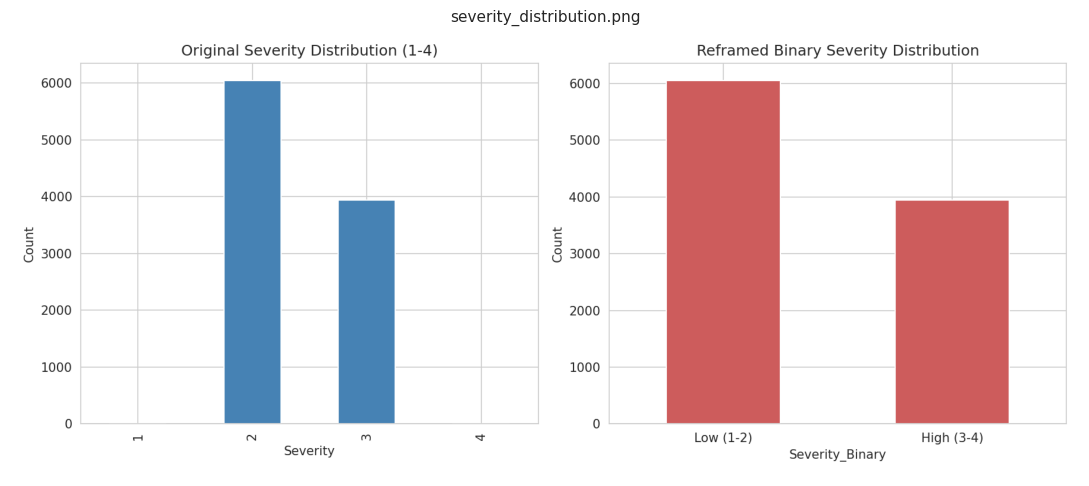

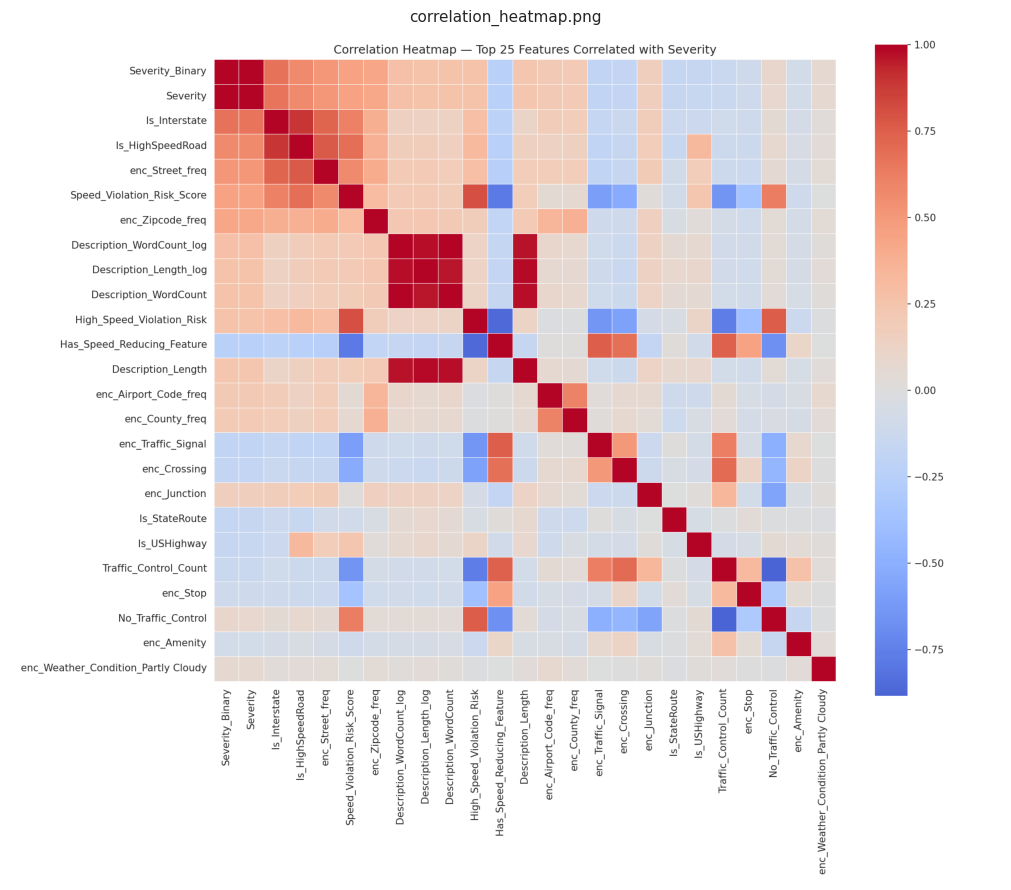

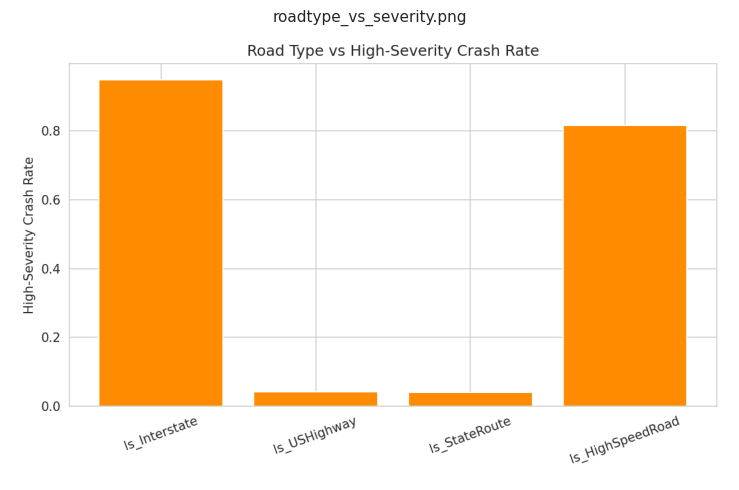

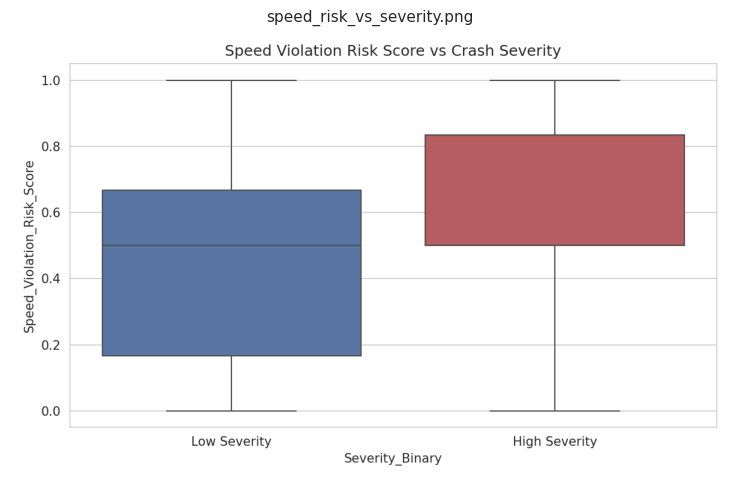

In [15]:
import matplotlib.pyplot as plt

def show_image(path, title=None, figsize=(11, 6)):
    """Display a PNG file inline."""
    img = plt.imread(path)
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.axis("off")
    if title:
        plt.title(title, fontsize=11)
    plt.tight_layout()
    plt.show()

show_image(f"{FIGURES_DIR}/severity_distribution.png", "severity_distribution.png", (11, 5))
show_image(f"{FIGURES_DIR}/correlation_heatmap.png", "correlation_heatmap.png", (11, 9))
show_image(f"{FIGURES_DIR}/roadtype_vs_severity.png", "roadtype_vs_severity.png", (8, 5))
show_image(f"{FIGURES_DIR}/speed_risk_vs_severity.png", "speed_risk_vs_severity.png", (8, 5))